# Verlustmuster

Abbildungen 15/16/23; Tabellen 7 und 21–25. Nicht Retained = Lost oder Referenzabweichung. Technisch fehlende Urteile bleiben eine eigene Kategorie. Die erste beobachtete Stufe ist bereits eine Zusammenfassung. Automatische Entitätstypen sind keine menschlich validierte Typisierung.

In [1]:
from pathlib import Path
from fractions import Fraction
from collections import Counter
from itertools import combinations
import hashlib, importlib.metadata, json, math, platform, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from threadpoolctl import threadpool_limits
from faktenretention.io import PROJECT_ROOT
from faktenretention.data import load_inputs, panel, length_values, reconstruct_qa, aggregate_articles, CELL, KEY
from faktenretention.protocol import METHODS, STAGES, WINDOWS, CONTRASTS, LABELS
threadpool_limits(limits=1)
SEED, B, N_FACTS = (32, 10000, 20)
DATA_DIR = PROJECT_ROOT / 'data'
OUT = PROJECT_ROOT / 'results/04_verlustmuster'
FIG = OUT
OUT.mkdir(parents=True, exist_ok=True)
COLORS = dict(zip(METHODS, ['#777777', '#0072B2', '#E69F00', '#009E73', '#CC79A7', '#D55E00']))
MARKERS = dict(zip(METHODS, ['o', 's', '^', 'D', 'v', 'P']))
LINESTYLES = dict(zip(METHODS, ['--', '-', '-.', '--', ':', '-']))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 26)

def export(frame, name):
    frame.to_csv(OUT / f'{name}.csv', index=False)

def fmt(x, d=2):
    return f'{x:.{d}f}'.replace('.', ',')

def savefig(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [2]:
inputs = load_inputs()
qa, article = panel(inputs)
facts = inputs['facts']
summaries = inputs['summaries']
articles = inputs['articles']
IDS = sorted(articles.article_id)
assert len(IDS) == 100

In [3]:
PATHKEY = ['article_id', 'method', 'canonical_fact_id']
R, L, D, M = ('retained', 'lost', 'reference_discordant', 'technical_missing')
STATES = [R, L, D, M]
NON = {L, D}
STATE_NAMES = {R: 'Retained', L: 'Lost', D: 'Referenzabweichend', M: 'Technisch fehlend'}
FIRSTS = ['500', '300', '150', '75', 'always_retained', 'undetermined']
FIRST_NAMES = {str(t): f'Erstmals bei {t} Wörtern' for t in STAGES}
FIRST_NAMES.update(always_retained='Bis 75 durchgehend Retained', undetermined='Nicht eindeutig bestimmbar')
qa = qa.drop(columns=[x for x in ['entity_type', 'fact'] if x in qa]).merge(facts[['article_id', 'canonical_fact_id',
    'entity_type', 'fact']], on=['article_id', 'canonical_fact_id'], validate='many_to_one')

## Faktenlaufbahnen und erster Nicht-Retained-Zeitpunkt

In [4]:
paths = qa.pivot(index=PATHKEY, columns='stage_target_words', values='label').reindex(columns=STAGES).reset_index()
assert len(paths) == 12000 and paths[STAGES].notna().all().all()
assert paths.groupby('method').size().eq(2000).all()
paths = paths.merge(facts[['article_id', 'canonical_fact_id', 'entity_type', 'fact']], on=['article_id',
    'canonical_fact_id'], validate='many_to_one')

def classify(seq):
    first_index = next((i for i, s in enumerate(seq) if s in NON), None)
    if first_index is None:
        first = 'undetermined' if M in seq else 'always_retained'
    else:
        first = 'undetermined' if M in seq[:first_index] else str(STAGES[first_index])
    observed_return = first_index is not None and R in seq[first_index + 1:]
    if first == 'undetermined':
        persistence = 'first_stage_undetermined'
    elif first == 'always_retained':
        persistence = 'always_retained'
    elif first_index == 3:
        persistence = 'first_at_final_stage'
    elif observed_return:
        persistence = 'observed_return'
    elif M in seq[first_index + 1:]:
        persistence = 'persistence_undetermined'
    else:
        persistence = 'all_later_non_retained'
    return (first, seq[first_index] if first_index is not None else '', persistence, observed_return)
assert classify([R, M, L, R])[:3] == ('undetermined', L, 'first_stage_undetermined')
assert classify([R, L, M, L])[:3] == ('300', L, 'persistence_undetermined')
assert classify([R, R, R, L])[:3] == ('75', L, 'first_at_final_stage')
assert classify([R, R, M, R])[0] == 'undetermined'
assert classify([L, R, L, L])[2] == 'observed_return'
assert classify([R, R, R, R])[0] == 'always_retained'
result = [classify(seq) for seq in paths[STAGES].itertuples(index=False, name=None)]
paths[['first_category', 'first_observed_nonretained_label', 'persistence', 'observed_return_any']] = pd.DataFrame(result,
    index=paths.index)
paths['n_missing'] = paths[STAGES].eq(M).sum(axis=1)
paths['label_sequence'] = paths[STAGES].agg(' → '.join, axis=1)
rng = np.random.default_rng(SEED)
draws = rng.integers(0, len(IDS), size=(B, len(IDS)))
weights = np.zeros((B, len(IDS)), dtype=np.int16)
np.add.at(weights, (np.repeat(np.arange(B), len(IDS)), draws.ravel()), 1)
assert weights.sum(axis=1).tolist() == [len(IDS)] * B

def estimate_ratio(frame, numerator, denominator):
    """Ratio of pooled counts; articles with no group facts contribute zero counts."""
    counts = frame.groupby('article_id')[[numerator, denominator]].sum().reindex(IDS, fill_value=0).to_numpy(dtype=float)
    k, v = counts.sum(axis=0)
    boot = weights @ counts
    ratios = np.divide(boot[:, 0], boot[:, 1], out=np.full(B, np.nan), where=boot[:, 1] > 0)
    ci = np.nanquantile(ratios, [0.025, 0.975]) if np.isfinite(ratios).any() else [np.nan, np.nan]
    return {'estimate': k / v if v else np.nan, 'ci_low': float(ci[0]), 'ci_high': float(ci[1]), 'n_numerator': int(k),
        'n_denominator': int(v), 'n_articles_denominator': int((counts[:, 1] > 0).sum()), 'bootstrap_draws_zero_denominator': int(np.isnan(ratios).sum())}
first_rows = []
for method in METHODS:
    sub = paths[paths.method.eq(method)].copy()
    sub['den'] = 1
    for cat in FIRSTS:
        sub['num'] = sub.first_category.eq(cat).astype(int)
        first_rows.append({'method': method, 'category': cat, 'category_name': FIRST_NAMES[cat], **estimate_ratio(sub, 'num', 'den')})
firsts = pd.DataFrame(first_rows)
assert firsts.groupby('method').n_numerator.sum().eq(2000).all()
export(firsts, 'erste_nicht_retained_stufe_95ci')
display(firsts.pivot(index='method', columns='category', values='n_numerator').reindex(index=METHODS,
    columns=FIRSTS).rename(index=LABELS, columns=FIRST_NAMES))

category,Erstmals bei 500 Wörtern,Erstmals bei 300 Wörtern,Erstmals bei 150 Wörtern,Erstmals bei 75 Wörtern,Bis 75 durchgehend Retained,Nicht eindeutig bestimmbar
method,,,,,,
Lead-k,487,532,388,254,332,7
Plain,898,122,101,229,634,16
Zero-Shot-CoT,560,103,295,489,544,9
Few-Shot-CoT,710,82,222,323,638,25
Auto-CoT,569,88,228,381,717,17
Automate-CoT,529,114,315,329,691,22


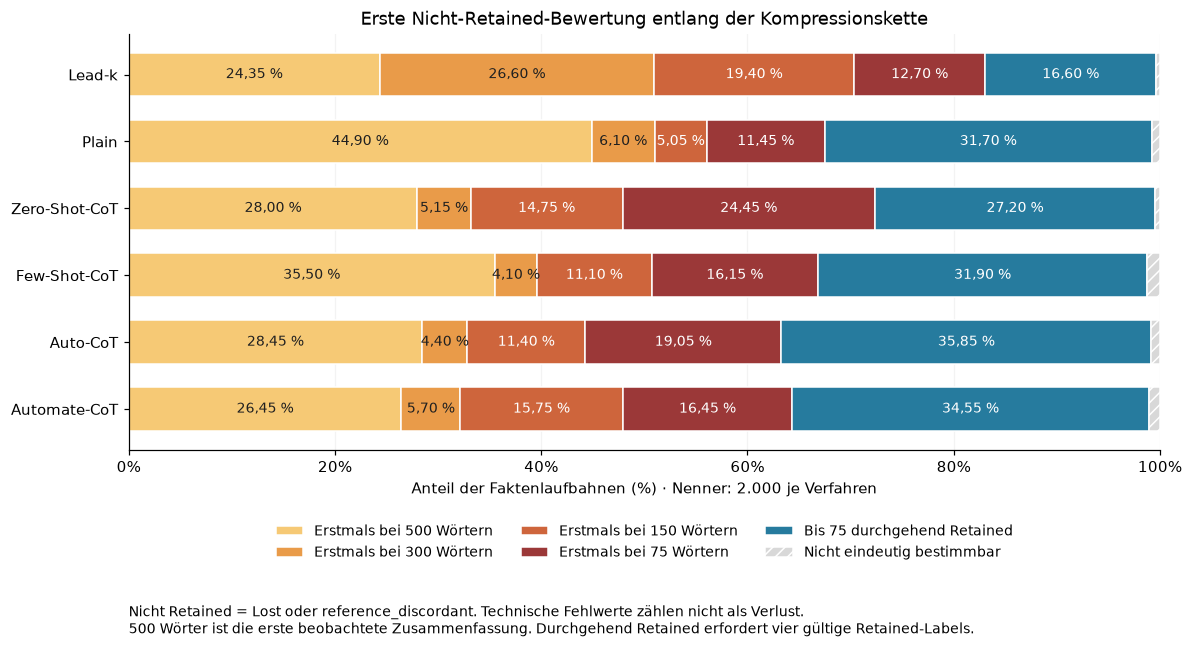

In [5]:
barcolors = ['#F6C975', '#E99B49', '#CE653C', '#9B3838', '#267B9E', '#D8D8D8']
fig, ax = plt.subplots(figsize=(12.5, 6.3))
left = np.zeros(len(METHODS))
for cat, color in zip(FIRSTS, barcolors):
    vals = firsts[firsts.category.eq(cat)].set_index('method').loc[METHODS, 'estimate'].to_numpy() * 100
    bars = ax.barh(np.arange(6), vals, left=left, color=color, edgecolor='white', height=0.65, label=FIRST_NAMES[cat],
        hatch='///' if cat == 'undetermined' else None)
    counts = firsts[firsts.category.eq(cat)].set_index('method').loc[METHODS, 'n_numerator']
    for i, (v, n) in enumerate(zip(vals, counts)):
        if v >= 3:
            ax.text(left[i] + v / 2, i, f'{fmt(v)} %', ha='center', va='center', fontsize=9, color='white' if cat in ['150',
                '75', 'always_retained'] else '#202020')
    left += vals
ax.set(yticks=np.arange(6), yticklabels=[LABELS[m] for m in METHODS], xlim=(0, 100), xlabel='Anteil der Faktenlaufbahnen (%) · Nenner: 2.000 je Verfahren',
    title='Erste Nicht-Retained-Bewertung entlang der Kompressionskette')
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.grid(axis='x', alpha=0.15)
ax.set_axisbelow(True)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False, fontsize=9)
fig.subplots_adjust(bottom=0.28, left=0.15)
fig.text(0.15, 0.015, 'Nicht Retained = Lost oder reference_discordant. Technische Fehlwerte zählen nicht als Verlust.\n500 Wörter ist die erste beobachtete Zusammenfassung. Durchgehend Retained erfordert vier gültige Retained-Labels.', fontsize=9)
savefig(fig, 'abb_15_erste_nicht_retained_stufe')

In [6]:
persistence_rows = []
for method in METHODS:
    sub = paths[paths.method.eq(method)].copy()
    risk = sub.first_category.isin(['500', '300', '150'])
    sub['den'] = risk.astype(int)
    for outcome in ['all_later_non_retained', 'observed_return', 'persistence_undetermined']:
        sub['num'] = (risk & sub.persistence.eq(outcome)).astype(int)
        persistence_rows.append({'method': method, 'outcome': outcome, **estimate_ratio(sub, 'num', 'den')})
persistence = pd.DataFrame(persistence_rows)
assert persistence.groupby('method').n_numerator.sum().equals(persistence.groupby('method').n_denominator.first())
export(persistence, 'persistenz_nach_erster_stufe_95ci')
path_overview = paths.groupby('method').agg(n_paths=('canonical_fact_id', 'size'), n_paths_with_missing=('n_missing',
    lambda s: int(s.gt(0).sum())), n_any_observed_return=('observed_return_any', 'sum'))
path_overview['n_first_at_75'] = paths[paths.first_category.eq('75')].groupby('method').size().reindex(path_overview.index, fill_value=0)
path_overview['n_first_undetermined'] = paths[paths.first_category.eq('undetermined')].groupby('method').size().reindex(path_overview.index, fill_value=0)
display(persistence[['method', 'outcome', 'n_numerator', 'n_denominator', 'estimate', 'ci_low', 'ci_high']].round(4))
display(path_overview.rename(index=LABELS))

,method,outcome,n_numerator,n_denominator,estimate,ci_low,ci_high
0,lead_k,all_later_non_retained,1384,1407,0.9837,0.9768,0.9899
1,lead_k,observed_return,21,1407,0.0149,0.0092,0.0212
2,lead_k,persistence_undetermined,2,1407,0.0014,0.0000,0.0036
3,plain,all_later_non_retained,1064,1121,0.9492,0.9365,0.9613
4,plain,observed_return,53,1121,0.0473,0.0353,0.0602
5,plain,persistence_undetermined,4,1121,0.0036,0.0009,0.0073
6,zero_shot_cot,all_later_non_retained,882,958,0.9207,0.9005,0.9397
7,zero_shot_cot,observed_return,72,958,0.0752,0.0563,0.0948
8,zero_shot_cot,persistence_undetermined,4,958,0.0042,0.0010,0.0085
9,few_shot_cot,all_later_non_retained,919,1014,0.9063,0.8871,0.9240


,n_paths,n_paths_with_missing,n_any_observed_return,n_first_at_75,n_first_undetermined
method,,,,,
Auto-CoT,2000,23,92,381,17
Automate-CoT,2000,27,81,329,22
Few-Shot-CoT,2000,37,86,323,25
Lead-k,2000,9,22,254,7
Plain,2000,20,53,229,16
Zero-Shot-CoT,2000,13,72,489,9


## Entitätstypen

Gepoolte Zählerquotienten mit Artikelbootstrap; keine Mittelung artikelweiser Quoten für diese Typentabellen.

In [7]:
type_counts = facts.groupby('entity_type').agg(n_facts=('canonical_fact_id', 'size'), n_articles=('article_id',
    'nunique')).sort_values('n_facts', ascending=False).reset_index()
type_counts['small_group'] = (type_counts.n_facts < 100) | (type_counts.n_articles < 30)
TYPES = type_counts.entity_type.tolist()
assert type_counts.n_facts.sum() == 2000
type_rows = []
for typ in TYPES:
    for method in METHODS:
        for stage in STAGES:
            sub = qa[qa.entity_type.eq(typ) & qa.method.eq(method) & qa.stage_target_words.eq(stage)].copy()
            sub['num'] = sub.label.eq(R).astype(int)
            sub['den'] = sub.analysis_eligible.astype(int)
            type_rows.append({'entity_type': typ, 'method': method, 'stage_target_words': stage, 'n_expected': len(sub),
                'n_missing': int(sub.technical_missing.sum()), 'n_lost': int(sub.label.eq(L).sum()),
                'n_reference_discordant': int(sub.label.eq(D).sum()), 'n_synthetic_not_found': int(sub.empty_output.sum()),
                **estimate_ratio(sub, 'num', 'den')})
type_retention = pd.DataFrame(type_rows).merge(type_counts, on='entity_type', validate='many_to_one')
assert len(type_retention) == len(TYPES) * 6 * 4
assert (type_retention.n_numerator + type_retention.n_lost + type_retention.n_reference_discordant).eq(type_retention.n_denominator).all()
assert (type_retention.n_denominator + type_retention.n_missing).eq(type_retention.n_expected).all()
export(type_retention, 'retention_entitaetstyp_methoden_stufen_95ci')
display(type_counts)

,entity_type,n_facts,n_articles,small_group
0,NUMBER,526,96,False
1,PERSON,420,97,False
2,LOCATION,255,93,False
3,DATE_TIME,216,90,False
4,OTHER,181,74,False
5,OBJECT,168,67,False
6,ORG,154,77,False
7,EVENT,80,53,True


In [8]:
type_counts['share_percent'] = 100 * type_counts.n_facts / 2000
per_type_article = facts.groupby(['entity_type', 'article_id']).size()
for typ in TYPES:
    type_counts.loc[type_counts.entity_type.eq(typ), 'median_facts_per_present_article'] = per_type_article.loc[typ].median()
    type_counts.loc[type_counts.entity_type.eq(typ), 'max_facts_per_present_article'] = per_type_article.loc[typ].max()
export(type_counts, 'tabelle_21_entitaetsverteilung')
for t in STAGES:
    table = type_retention[type_retention.stage_target_words.eq(t)].pivot(index='entity_type', columns='method',
        values='estimate').reindex(index=TYPES, columns=METHODS)
    export(table.reset_index(), f'tabelle_{22 + STAGES.index(t)}_entitaetsretention_{t}')

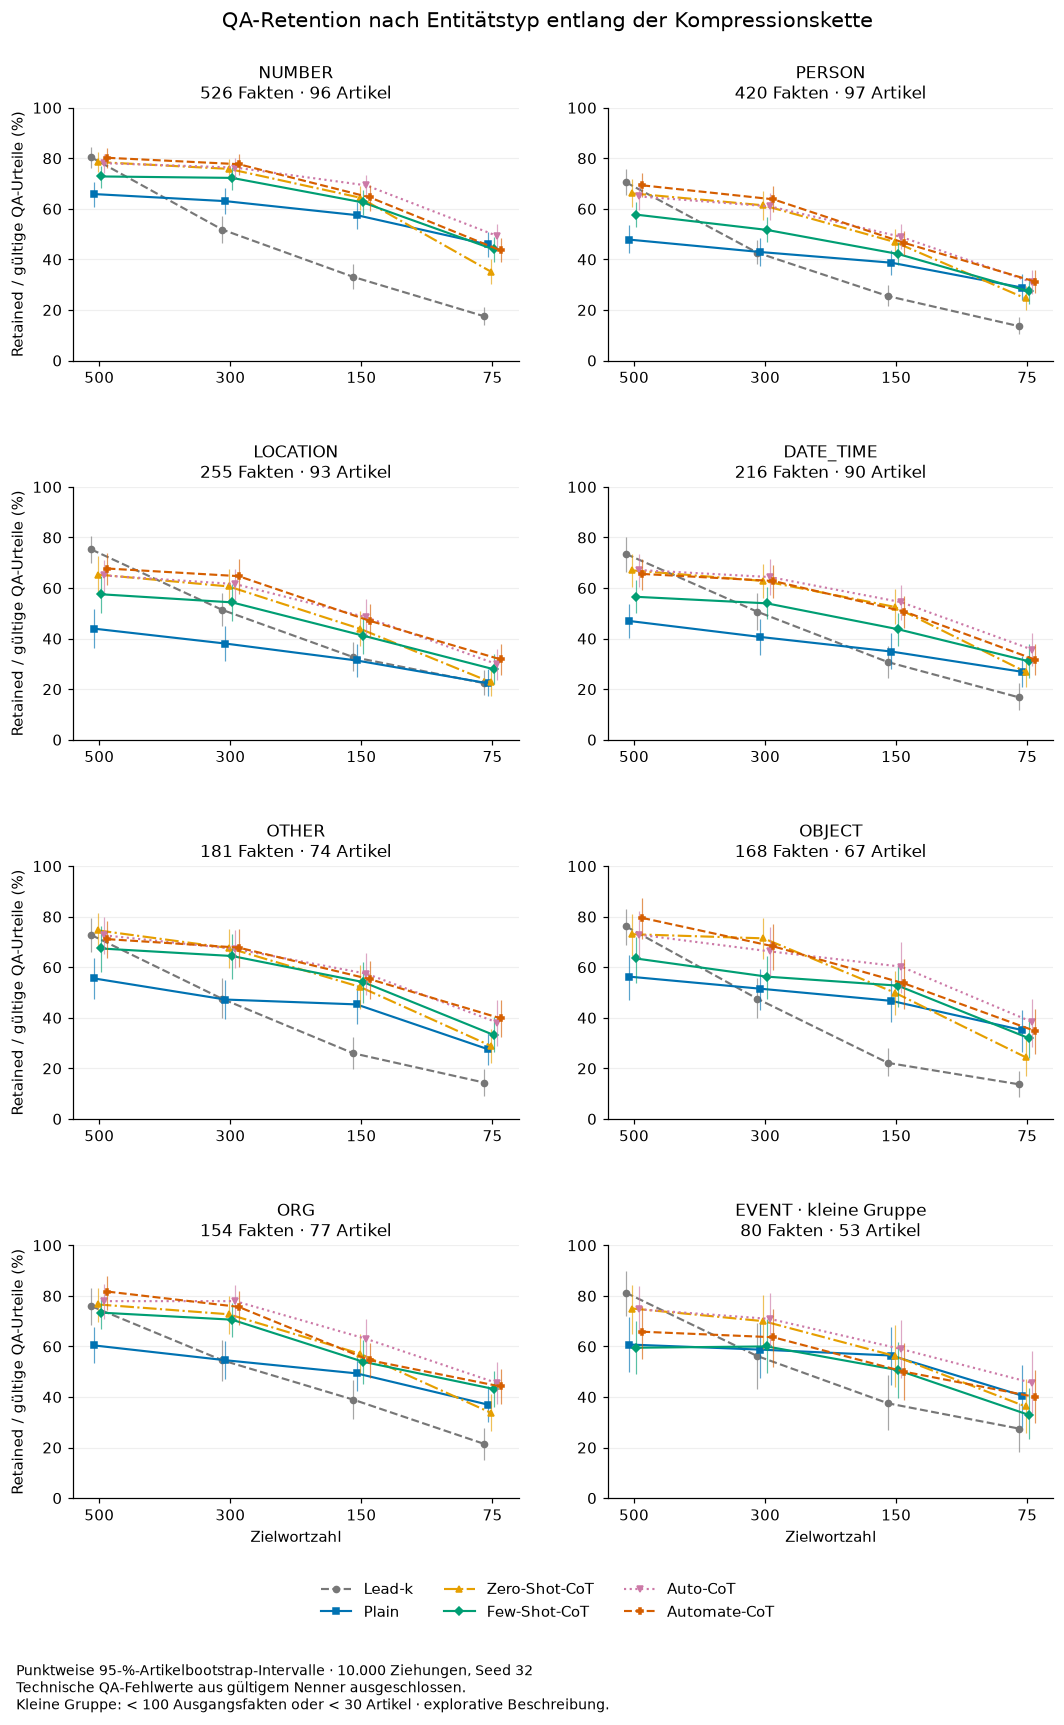

In [9]:
x = np.arange(4)
linestyles = ['--', '-', '-.', '-', ':', '--']
fig, axes = plt.subplots(4, 2, figsize=(11.5, 16), sharex=True, sharey=True)
for panel, (ax, typ) in enumerate(zip(axes.flat, TYPES)):
    counts = type_counts.set_index('entity_type').loc[typ]
    for i, method in enumerate(METHODS):
        sub = type_retention[type_retention.entity_type.eq(typ) & type_retention.method.eq(method)].set_index('stage_target_words').loc[STAGES]
        y = 100 * sub.estimate.to_numpy()
        offset = (i - 2.5) * 0.025
        ax.vlines(x + offset, 100 * sub.ci_low, 100 * sub.ci_high, color=COLORS[method], alpha=0.65, linewidth=0.8)
        ax.plot(x + offset, y, color=COLORS[method], marker=MARKERS[method], linestyle=linestyles[i],
            linewidth=1.4, markersize=4, label=LABELS[method])
    small = ' · kleine Gruppe' if counts.small_group else ''
    ax.set_title(f'{typ}{small}\n{int(counts.n_facts)} Fakten · {int(counts.n_articles)} Artikel', fontsize=11)
    ax.set(xticks=x, xticklabels=STAGES, yticks=np.arange(0, 101, 20), ylim=(0, 100), xlim=(-0.2, 3.2))
    ax.grid(axis='y', alpha=0.2)
    ax.tick_params(labelbottom=True, labelleft=True)
    if panel % 2 == 0:
        ax.set_ylabel('Retained / gültige QA-Urteile (%)')
    if panel >= 6:
        ax.set_xlabel('Zielwortzahl')
fig.subplots_adjust(top=0.93, bottom=0.14, hspace=0.5, wspace=0.2)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.1), ncol=3, frameon=False)
fig.suptitle('QA-Retention nach Entitätstyp entlang der Kompressionskette', fontsize=14, y=0.985)
fig.text(0.08, 0.02, 'Punktweise 95-%-Artikelbootstrap-Intervalle · 10.000 Ziehungen, Seed 32\nTechnische QA-Fehlwerte aus gültigem Nenner ausgeschlossen.\nKleine Gruppe: < 100 Ausgangsfakten oder < 30 Artikel · explorative Beschreibung.', fontsize=9)
savefig(fig, 'abb_23_entitaetsretention')

## Bedingte Verluste

Die Manuskriptabbildung poolt Zero-Shot-CoT, Auto-CoT und Automate-CoT; pro Übergang zählen nur gültige Ausgangs- und Folgeurteile.

In [10]:
GENERATIVE = [m for m in METHODS if m != 'lead_k']
loss_rows = []
comparison_groups = [('Drei generative Verfahren gepoolt', ['zero_shot_cot', 'auto_cot', 'automate_cot'])]
for group_name, method_set in comparison_groups:
    selected = paths[paths.method.isin(method_set)]
    for before, after in zip(STAGES[:-1], STAGES[1:]):
        pair = selected[['article_id', 'canonical_fact_id', 'entity_type', before, after]].copy()
        pair['valid_pair'] = ~pair[before].eq(M) & ~pair[after].eq(M)
        pair = pair[pair.valid_pair].copy()
        pair['retained_start'] = pair[before].eq(R)
        pair['loss_to_nonretained'] = pair.retained_start & pair[after].isin(NON)
        pair['loss_to_lost'] = pair.retained_start & pair[after].eq(L)
        pair['loss_to_reference_discordant'] = pair.retained_start & pair[after].eq(D)
        pair['return_to_retained'] = pair[before].isin(NON) & pair[after].eq(R)
        pair['net_loss'] = pair.loss_to_nonretained.astype(int) - pair.return_to_retained.astype(int)
        pair['valid'] = 1
        for typ, sub in pair.groupby('entity_type'):
            per_article = sub.groupby('article_id')[['loss_to_nonretained', 'retained_start', 'return_to_retained',
                'net_loss', 'valid', 'loss_to_lost', 'loss_to_reference_discordant']].sum().reindex(IDS, fill_value=0)
            totals = per_article.sum()
            boot = weights @ per_article.to_numpy(dtype=float)
            loss_ratio = np.divide(boot[:, 0], boot[:, 1], out=np.full(B, np.nan), where=boot[:, 1] > 0)
            loss_ci = np.nanquantile(loss_ratio, [0.025, 0.975])
            net_ratio = boot[:, 3] / boot[:, 4]
            net_ci = np.quantile(net_ratio, [0.025, 0.975])
            loss_rows.append({'method_group': group_name, 'transition': f'{before}→{after}', 'from_stage': before,
                'to_stage': after, 'entity_type': typ, 'n_facts': int(type_counts.set_index('entity_type').loc[typ,
                'n_facts']), 'n_articles_with_type': int(type_counts.set_index('entity_type').loc[typ,
                'n_articles']), 'n_valid_pairs': int(totals.valid), 'n_retained_at_start': int(totals.retained_start),
                'n_retained_to_nonretained': int(totals.loss_to_nonretained), 'n_to_lost': int(totals.loss_to_lost),
                'n_to_reference_discordant': int(totals.loss_to_reference_discordant), 'loss_given_retained': totals.loss_to_nonretained / totals.retained_start if totals.retained_start else np.nan,
                'loss_ci_low': loss_ci[0], 'loss_ci_high': loss_ci[1], 'n_nonretained_to_retained': int(totals.return_to_retained),
                'net_loss_pp': 100 * totals.net_loss / totals.valid if totals.valid else np.nan, 'net_loss_ci_low_pp': 100 * net_ci[0],
                'net_loss_ci_high_pp': 100 * net_ci[1], 'small_group': bool(type_counts.set_index('entity_type').loc[typ,
                'small_group']), 'bootstrap_draws_zero_risk_denominator': int(np.isnan(loss_ratio).sum())})
loss_by_type = pd.DataFrame(loss_rows)
loss_by_type['loss_percent'] = 100 * loss_by_type.loss_given_retained
loss_by_type['loss_ci_low_percent'] = 100 * loss_by_type.loss_ci_low
loss_by_type['loss_ci_high_percent'] = 100 * loss_by_type.loss_ci_high
loss_by_type['rank_by_loss_rate'] = loss_by_type.groupby(['method_group', 'transition']).loss_percent.rank(method='min',
    ascending=False).astype(int)
export(loss_by_type, 'verlust_entitaetstyp_uebergaenge_95ci')

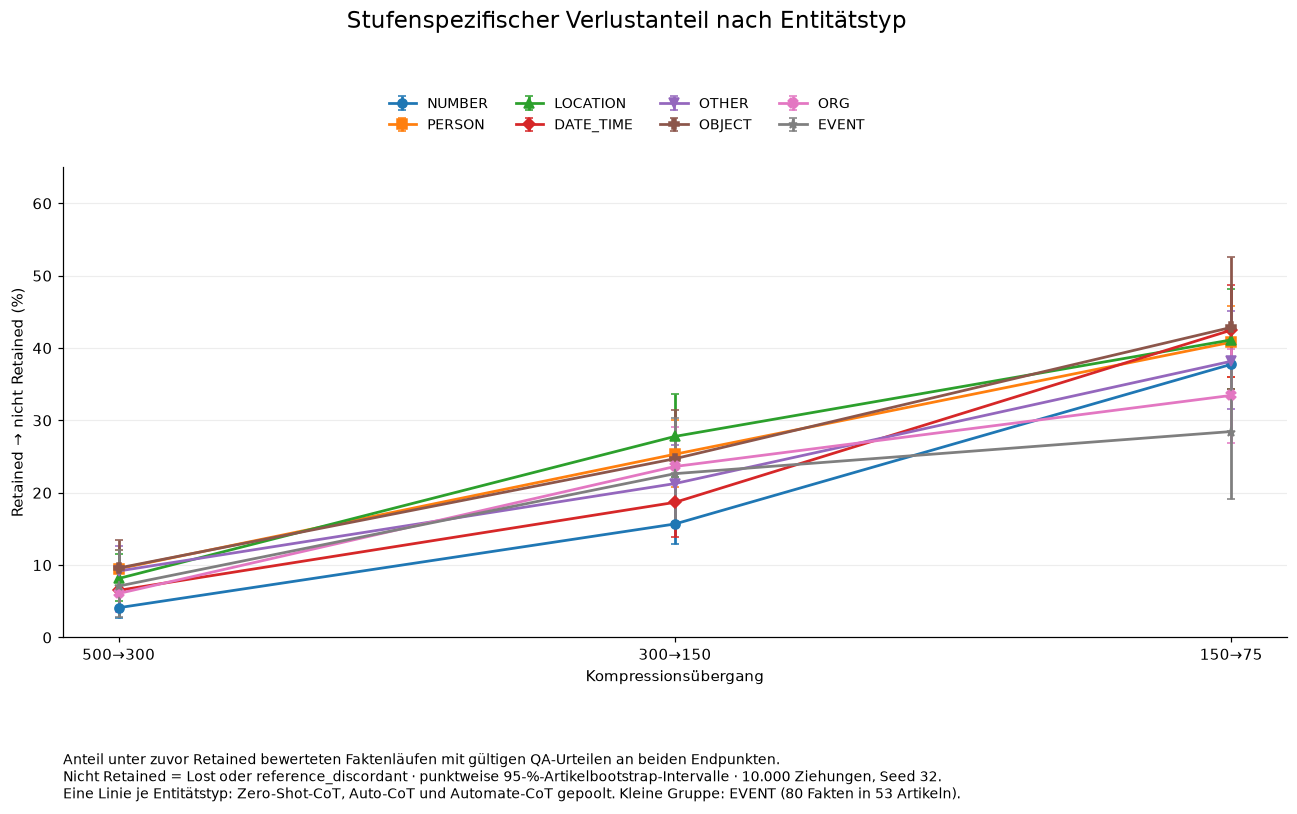

In [11]:
PLOT_GROUP = 'Drei generative Verfahren gepoolt'
TYPE_COLORS = dict(zip(TYPES, plt.get_cmap('tab10').colors[:len(TYPES)]))
TYPE_MARKERS = dict(zip(TYPES, ['o', 's', '^', 'D', 'v', 'P', 'X', '*']))
transition_order = ['500→300', '300→150', '150→75']
xx = np.arange(3)
fig, ax = plt.subplots(figsize=(12.5, 7.5))
for typ in TYPES:
    sub = loss_by_type[loss_by_type.entity_type.eq(typ) & loss_by_type.method_group.eq(PLOT_GROUP)].set_index('transition').loc[transition_order]
    y = sub.loss_percent.to_numpy()
    yerr = np.vstack([y - sub.loss_ci_low_percent.to_numpy(), sub.loss_ci_high_percent.to_numpy() - y])
    ax.errorbar(xx, y, yerr=yerr, color=TYPE_COLORS[typ], marker=TYPE_MARKERS[typ], linestyle='-', linewidth=1.8,
        markersize=6, capsize=2.5, label=typ)
ax.set(xticks=xx, xticklabels=transition_order, ylim=(0, 65), yticks=np.arange(0, 66, 10), xlabel='Kompressionsübergang',
    ylabel='Retained → nicht Retained (%)')
ax.grid(axis='y', alpha=0.22)
ax.set_axisbelow(True)
fig.suptitle('Stufenspezifischer Verlustanteil nach Entitätstyp', fontsize=15, y=0.98)
fig.legend(loc='upper center', bbox_to_anchor=(0.5, 0.89), ncol=4, frameon=False, fontsize=9)
fig.subplots_adjust(top=0.79, bottom=0.22, left=0.09, right=0.98)
fig.text(0.09, 0.025, 'Anteil unter zuvor Retained bewerteten Faktenläufen mit gültigen QA-Urteilen an beiden Endpunkten.\nNicht Retained = Lost oder reference_discordant · punktweise 95-%-Artikelbootstrap-Intervalle · 10.000 Ziehungen, Seed 32.\nEine Linie je Entitätstyp: Zero-Shot-CoT, Auto-CoT und Automate-CoT gepoolt. Kleine Gruppe: EVENT (80 Fakten in 53 Artikeln).', fontsize=9)
savefig(fig, 'abb_16_bedingte_entitaetsverluste')

## Lead-k-Präfixe und die beiden Rückwechsel-Nenner

In [12]:
lead = summaries[summaries.method.eq('lead_k')].set_index('article_id')
prefix_rows = []
for a in IDS:
    for before, after in zip(STAGES[:-1], STAGES[1:]):
        prefix_rows.append({'article_id': a, 'from_stage': before, 'to_stage': after, 'nested_prefix': lead.loc[a,
            f'summary_{before}'].startswith(lead.loc[a, f'summary_{after}'])})
prefix_audit = pd.DataFrame(prefix_rows)
export(prefix_audit, 'lead_k_praefixpruefung')
display(prefix_audit.groupby(['from_stage', 'to_stage']).nested_prefix.agg(['sum', 'count']))
from faktenretention.text_rules import lead_k
for a in IDS:
    previous = articles.set_index('article_id').loc[a, 'article']
    for t in STAGES:
        actual = lead.loc[a, f'summary_{t}']
        assert actual == lead_k(previous, t)
        previous = actual
assert prefix_audit.nested_prefix.all()
lead_paths = paths[paths.method.eq('lead_k')].copy()
early = lead_paths.first_category.isin(['500', '300', '150'])
historical_n = int((early & lead_paths.persistence.eq('observed_return')).sum())
complete = lead_paths[STAGES].ne(M).all(axis=1)
valid_pair = np.zeros(len(lead_paths), dtype=bool)
return_pair = np.zeros(len(lead_paths), dtype=bool)
for before, after in combinations(STAGES, 2):
    valid = lead_paths[before].ne(M) & lead_paths[after].ne(M)
    valid_pair |= valid.to_numpy()
    return_pair |= (valid & lead_paths[before].isin(NON) & lead_paths[after].eq(R)).to_numpy()
assert historical_n == 21 and early.sum() == 1407
assert return_pair.sum() == 22 and valid_pair.sum() == 1999
returns = pd.DataFrame([dict(definition='Erste Nicht-R-Stufe vor 75 eindeutig', numerator=historical_n,
    denominator=int(early.sum())), dict(definition='Mindestens ein gültiges Stufenpaar, alle sechs Paare',
    numerator=int(return_pair.sum()), denominator=int(valid_pair.sum()))])
returns['percent'] = 100 * returns.numerator / returns.denominator
export(returns, 'lead_k_rueckwechsel_bezugsgruppen')
display(returns)

,,sum,count
from_stage,to_stage,,
150,75,100,100
300,150,100,100
500,300,100,100


,definition,numerator,denominator,percent
0,Erste Nicht-R-Stufe vor 75 eindeutig,21,1407,1.492537
1,"Mindestens ein gültiges Stufenpaar, alle sechs...",22,1999,1.100550
